# Analysis of Steady-State Pumping Tests Using the Dupuit–Thiem Method

**Hydraulic Methods – Hydrogeology, KIT**

This notebook solves two exercises for a **confined** (a) and an **unconfined** (b) aquifer. Input data are grouped in separate code cells and can be modified to analyze other pumping tests.

We assume steady-state, radially symmetric flow toward a fully penetrating well in a homogeneous aquifer. The method neglects well losses and local departures from the Dupuit assumption (predominantly horizontal flow).

**Required packages:** NumPy and Matplotlib.

## Theory

### Confined aquifer

For two observation wells with $r_2>r_1$ and $s_1>s_2$:

$$Q=2\pi T\,\frac{s_1-s_2}{\ln(r_2/r_1)},\qquad T=k_f M.$$

For multiple observation wells, plot drawdown $s$ against **logarithmic distance** $\log_{10}(r)$ and fit a straight line:

$$s=a+b\log_{10}(r)\qquad(b<0).$$

The drawdown difference over one logarithmic decade is $\Delta s=-b$. Therefore:

$$\boxed{T=\frac{Q\ln(10)}{2\pi\Delta s}},\qquad\boxed{k_f=\frac{T}{M}}.$$

The extrapolated **radius of influence $R$** is the intersection of the fitted line with $s=0$:

$$\boxed{R=10^{-a/b}}.$$

Alternatively, for an individual observation well and a known transmissivity:

$$\boxed{R_i=r_i\exp\left(\frac{2\pi T s_i}{Q}\right)}.$$

**Units:** $Q$ in m³/s; $r$, $s$, and $M$ in m; $T$ in m²/s; $k_f$ in m/s.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# Consistent plot formatting
plt.rcParams.update({"figure.figsize": (9, 5.5), "font.size": 11})

## Exercise a: Steady-state pumping test in a confined aquifer

**Given:** $Q=9$ L/s, aquifer thickness $M=10$ m, and drawdown measurements at four observation wells. Determine transmissivity $T$, hydraulic conductivity $k_f$, and radius of influence $R$.

In [2]:
# --- Input data for exercise a ---
messstellen = ["M1", "M2", "M3", "M4"]
r = np.array([0.80, 30.0, 90.0, 215.0])  # Distance [m]
s = np.array([2.24, 1.09, 0.72, 0.25])   # Drawdown [m]
Q_l_s = 9.0                                  # Pumping rate [L/s]
M = 10.0                                    # Aquifer thickness [m]

Q = Q_l_s / 1000.0  # Convert to m³/s

assert np.all(r > 0) and np.all(s >= 0), "r must be > 0 and s >= 0."
assert Q > 0 and M > 0, "Q and M must be positive."
assert len(r) == len(s) == len(messstellen), "Inconsistent numbers of observations."

print("Well          r [m]   s [m]")
for name, ri, si in zip(messstellen, r, s):
    print(f"{name:>7}   {ri:6.2f}   {si:5.2f}")
print(f"\nQ = {Q:.4f} m³/s; M = {M:.1f} m")

Well          r [m]   s [m]
     M1     0.80    2.24
     M2    30.00    1.09
     M3    90.00    0.72
     M4   215.00    0.25

Q = 0.0090 m³/s; M = 10.0 m


### 1. Straight-line method: transmissivity and hydraulic conductivity

`np.polyfit` performs linear regression of $s$ against $\log_{10}(r)$. The negative slope $b$ corresponds to the drawdown difference $\Delta s$ per logarithmic decade. **All four observation wells** are used initially.

In [3]:
# Fitted line s = a + b * log10(r)
b, a = np.polyfit(np.log10(r), s, 1)

delta_s = -b                   # Drawdown difference per decade [m]
T = Q * np.log(10) / (2 * np.pi * delta_s)
k_f = T / M
R = 10 ** (-a / b)            # Radius of influence: intercept at s = 0 [m]

# Goodness of fit for semi-logarithmic regression
s_berechnet = a + b * np.log10(r)
ss_res = np.sum((s - s_berechnet) ** 2)
ss_tot = np.sum((s - np.mean(s)) ** 2)
r_quadrat = 1 - ss_res / ss_tot

print("Linear regression using all four observation wells:")
print(f"  s = {a:.4f} {b:+.4f} * log10(r)")
print(f"  Delta s = {delta_s:.3f} m per decade")
print(f"  T       = {T:.3e} m²/s")
print(f"  k_f     = {k_f:.3e} m/s")
print(f"  R       = {R:.0f} m")
print(f"  R²      = {r_quadrat:.3f}")

Linear regression using all four observation wells:
  s = 2.1964 -0.7915 * log10(r)
  Delta s = 0.792 m per decade
  T       = 4.167e-03 m²/s
  k_f     = 4.167e-04 m/s
  R       = 595 m
  R²      = 0.991


### 2. Graphical determination of the radius of influence

The radius of influence $R$ is determined by **extrapolating the fitted line to zero drawdown ($s=0$)**. With scattered measurements, the result is sensitive to the fitted line.

For illustration, a second line is fitted to **M1–M3**. This is **not an automated outlier-removal procedure**; it illustrates why manual graphical interpretations can yield different radii of influence.

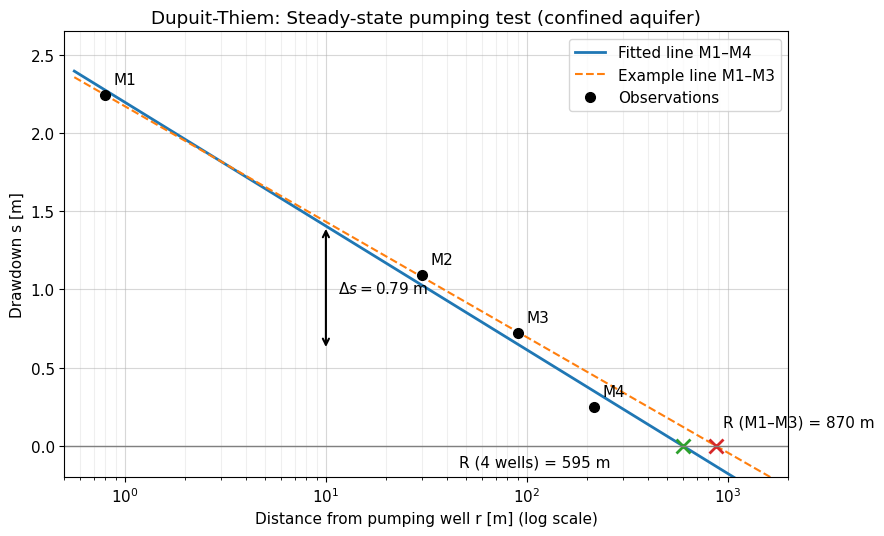

Alle 4 Messstellen: T = 4.167e-03 m²/s, R = 595 m
Nur M1–M3:          T = 4.466e-03 m²/s, R = 870 m


In [4]:
# Alternative fit illustrating graphical uncertainty:
# Fitted line using the first three observation wells
b_123, a_123 = np.polyfit(np.log10(r[:3]), s[:3], 1)
R_123 = 10 ** (-a_123 / b_123)
T_123 = Q * np.log(10) / (2 * np.pi * (-b_123))

r_plot = np.geomspace(min(r) * 0.7, max(2000, R_123 * 1.5), 400)
s_fit = a + b * np.log10(r_plot)
s_fit_123 = a_123 + b_123 * np.log10(r_plot)

fig, ax = plt.subplots()
ax.semilogx(r_plot, s_fit, label="Fitted line M1–M4", linewidth=2)
ax.semilogx(r_plot, s_fit_123, linestyle="--", label="Example line M1–M3")
ax.semilogx(r, s, "ko", markersize=7, label="Observations")

for name, ri, si in zip(messstellen, r, s):
    ax.annotate(name, (ri, si), xytext=(6, 8), textcoords="offset points")

# Mark both extrapolated intercepts at s = 0
ax.plot(R, 0, marker="x", markersize=10, markeredgewidth=2)
ax.plot(R_123, 0, marker="x", markersize=10, markeredgewidth=2)
ax.annotate(f"R (4 wells) = {R:.0f} m", (R, 0), xytext=(-52, -15),
            textcoords="offset points", ha="right")
ax.annotate(f"R (M1–M3) = {R_123:.0f} m", (R_123, 0), xytext=(5, 14),
            textcoords="offset points")

# Delta s over exactly one logarithmic decade (10 m -> 100 m)
x_decade = 10.0
s_oben = a + b * np.log10(x_decade)
s_unten = a + b * np.log10(10 * x_decade)
ax.annotate("", xy=(x_decade, s_oben), xytext=(x_decade, s_unten),
            arrowprops={"arrowstyle": "<->", "lw": 1.5})
ax.annotate(rf"$\Delta s = {delta_s:.2f}$ m", (x_decade, (s_oben+s_unten)/2),
            xytext=(9, 0), textcoords="offset points", va="center")

ax.axhline(0, color="gray", linewidth=1)
ax.set(xlabel="Distance from pumping well r [m] (log scale)",
       ylabel="Drawdown s [m]",
       title="Dupuit-Thiem: Steady-state pumping test (confined aquifer)")
ax.set_xlim(0.5, max(2000, R_123 * 1.5))
ax.set_ylim(-0.20, 2.65)
ax.grid(True, which="major", alpha=0.5)
ax.grid(True, which="minor", alpha=0.2)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

print(f"Alle 4 Messstellen: T = {T:.3e} m²/s, R = {R:.0f} m")
print(f"Nur M1–M3:          T = {T_123:.3e} m²/s, R = {R_123:.0f} m")

### 3. Calculating the radius of influence from individual observation wells

Using the transmissivity determined above, calculate $R_i$ separately for each observation well. The differences illustrate the uncertainty of this extrapolated quantity. The result given in the exercise solution for M1 is also reproduced using the rounded value $T=4\cdot10^{-3}$ m²/s.

In [5]:
# Individual radii using transmissivity from regression (M1–M4)
R_einzeln = r * np.exp(2 * np.pi * T * s / Q)

print("Calculated radii of influence using regression-derived T:")
for name, Ri in zip(messstellen, R_einzeln):
    print(f"  {name}: R = {Ri:6.1f} m")
print(f"  Arithmetic mean: {R_einzeln.mean():.1f} m")
print(f"  Radius from regression line: {R:.1f} m")

T_gerundet = 4.0e-3  # Rounded reference solution
R_M1 = r[0] * np.exp(2 * np.pi * T_gerundet * s[0] / Q)
print(f"\nMit T = 4.0e-3 m²/s from the reference solution: R(M1) = {R_M1:.0f} m")

Calculated radii of influence using regression-derived T:
  M1: R =  540.8 m
  M2: R =  714.8 m
  M3: R =  730.9 m
  M4: R =  444.9 m
  Arithmetic mean: 607.9 m
  Radius from regression line: 595.5 m

Mit T = 4.0e-3 m²/s from the reference solution: R(M1) = 417 m


**Comparison with the exercise solution (a):** The provided solution gives $T\approx4\cdot10^{-3}$ m²/s and $k_f\approx4\cdot10^{-4}$ m/s, consistent with the regression results.

The exercise sheet gives a graphical estimate of **700–900 m** and an individual calculation of approximately **419 m** for M1. The fitted line through M1–M3 gives approximately **870 m**, whereas regression using **all four wells yields approximately 595 m**. This difference illustrates the sensitivity of extrapolation to the fitted line rather than an arithmetic error. The radius of influence is therefore a **model-dependent approximation**.

## Exercise b: Steady-state pumping test in an unconfined aquifer

Read the following values from the exercise diagram:

- $Q=3$ L/s, $r_1=5$ m, $r_2=25$ m
- $h_1=11$ m, $h_2=12$ m (water-table elevations above the impermeable base)
- $H=14$ m (initial saturated thickness; not needed for the direct equation)

The Dupuit–Thiem equation for an **unconfined** aquifer is:

$$Q=\pi k_f\,\frac{h_2^2-h_1^2}{\ln(r_2/r_1)}.$$

Solving for hydraulic conductivity:

$$\boxed{k_f=\frac{Q\ln(r_2/r_1)}{\pi(h_2^2-h_1^2)}}.$$


In [6]:
# --- Input data for exercise b ---
Q_b_l_s = 3.0   # [l/s]
r1 = 5.0       # [m]
r2 = 25.0      # [m]
h1 = 11.0      # [m]
h2 = 12.0      # [m]
H = 14.0       # [m], for optional check with corrected drawdown

Q_b = Q_b_l_s / 1000.0
assert 0 < r1 < r2 and 0 < h1 < h2 <= H and Q_b > 0

kf_frei = Q_b * np.log(r2 / r1) / (np.pi * (h2**2 - h1**2))

print("Steady-state pumping test in an unconfined aquifer:")
print(f"  Q   = {Q_b:.4f} m³/s")
print(f"  r1  = {r1:.1f} m, r2 = {r2:.1f} m")
print(f"  h1  = {h1:.1f} m, h2 = {h2:.1f} m")
print(f"  k_f = {kf_frei:.3e} m/s")

Steady-state pumping test in an unconfined aquifer:
  Q   = 0.0030 m³/s
  r1  = 5.0 m, r2 = 25.0 m
  h1  = 11.0 m, h2 = 12.0 m
  k_f = 6.682e-05 m/s


### Optional check using corrected drawdown

As described in the exercise sheet, **corrected drawdown** $s'$ can be calculated from measured drawdown $s=H-h$:

$$s'=s-\frac{s^2}{2H}.$$

This leads to an equation of the same form as for a confined aquifer:

$$Q=2\pi H k_f\,\frac{s'_1-s'_2}{\ln(r_2/r_1)}.$$

Both methods must give the same hydraulic conductivity.

In [7]:
s1 = H - h1
s2 = H - h2
s1_korr = s1 - s1**2 / (2 * H)
s2_korr = s2 - s2**2 / (2 * H)

kf_korr = Q_b * np.log(r2 / r1) / (2 * np.pi * H * (s1_korr - s2_korr))

print(f"Measured drawdowns:  s1 = {s1:.3f} m, s2 = {s2:.3f} m")
print(f"Corrected drawdowns: s1' = {s1_korr:.3f} m, s2' = {s2_korr:.3f} m")
print(f"k_f (direct equation) = {kf_frei:.6e} m/s")
print(f"k_f (corrected)        = {kf_korr:.6e} m/s")

# Both equations are algebraically equivalent.
assert np.isclose(kf_frei, kf_korr)

Measured drawdowns:  s1 = 3.000 m, s2 = 2.000 m
Corrected drawdowns: s1' = 2.679 m, s2' = 1.857 m
k_f (direct equation) = 6.682174e-05 m/s
k_f (corrected)        = 6.682174e-05 m/s


### Drawdown plot

With two observation wells, a straight line can be plotted on semi-logarithmic axes. Measured and corrected drawdowns are compared. With only two measurements, the straight line is not a statistical regression that independently tests linearity.

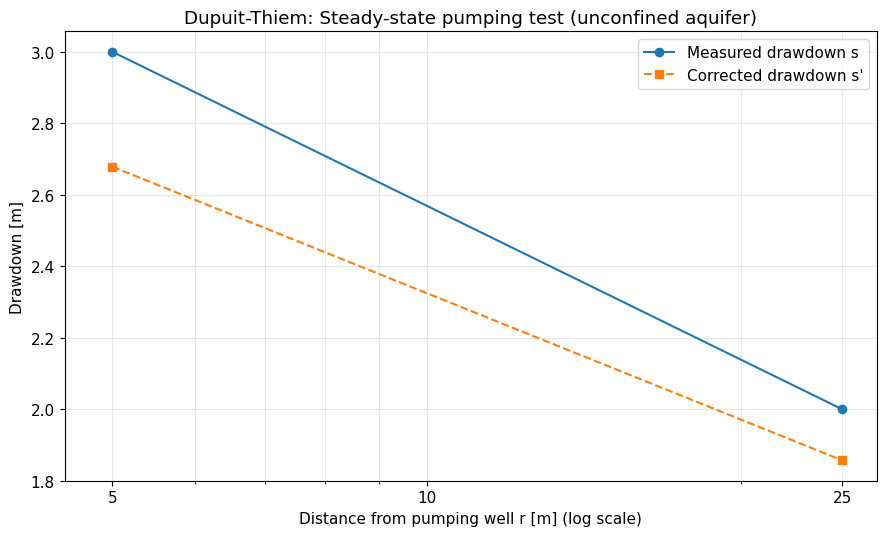

In [8]:
r_b = np.array([r1, r2])
s_b = np.array([s1, s2])
s_b_korr = np.array([s1_korr, s2_korr])

fig, ax = plt.subplots()
ax.semilogx(r_b, s_b, "o-", label="Measured drawdown s")
ax.semilogx(r_b, s_b_korr, "s--", label="Corrected drawdown s'")
ax.set(xlabel="Distance from pumping well r [m] (log scale)",
       ylabel="Drawdown [m]",
       title="Dupuit-Thiem: Steady-state pumping test (unconfined aquifer)")
from matplotlib.ticker import FixedLocator, FixedFormatter, NullFormatter
ax.xaxis.set_major_locator(FixedLocator([5, 10, 25]))
ax.xaxis.set_major_formatter(FixedFormatter(["5", "10", "25"]))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlim(4.5, 27)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Summary of results

| Exercise | Parameter | Result |
|:--|:--|:--|
| a: confined aquifer | Transmissivity $T$ (M1–M4 regression) | $\approx4.17\cdot10^{-3}$ m²/s |
| a: confined aquifer | Hydraulic conductivity $k_f$ (M1–M4 regression) | $\approx4.17\cdot10^{-4}$ m/s |
| a: confined aquifer | Radius of influence $R$ (M1–M4 regression) | $\approx595$ m |
| a: confined aquifer | Radius of influence $R$ (M1–M3 example line) | $\approx870$ m |
| b: unconfined aquifer | Hydraulic conductivity $k_f$ | $\approx6.68\cdot10^{-5}$ m/s |

**Using your own data:** Replace the input values in the cells for exercises a and b, then rerun the relevant cells. At least two observation wells are required for the confined-aquifer calculation; with more than two wells, a regression line can be fitted. Both approaches require steady-state conditions.